In [29]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statistics

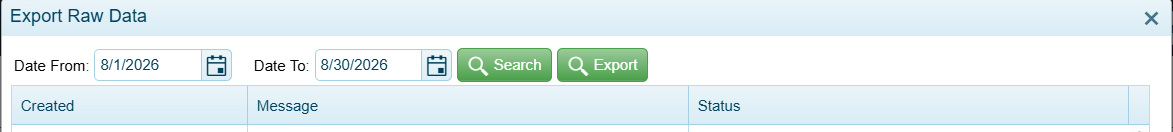

In [30]:
raw_data=pd.read_excel(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\la_concepcion\Export (1).xlsx')
raw_data.info()
#Raw data since 01-08-2026 until 30-08-2026. UTC.

<class 'pandas.DataFrame'>
RangeIndex: 5901 entries, 0 to 5900
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  5901 non-null   str  
 1   Message  5901 non-null   str  
 2   Status   5901 non-null   str  
dtypes: str(3)
memory usage: 138.4 KB


In [31]:
aux=pd.DataFrame()
aux=raw_data
aux['Headers']='NaN'

for i in range(0,aux.shape[0]):
    aux.iloc[i,3]=aux.iloc[i,2][0:8]

aux['Headers'].value_counts()

Headers
0x252513    2982
0x252521    2132
0x252514     746
0x252501      23
0x252511      18
Name: count, dtype: int64

In [32]:
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5901 entries, 0 to 5900
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  5901 non-null   str  
 1   Message  5901 non-null   str  
 2   Status   5901 non-null   str  
 3   Headers  5901 non-null   str  
dtypes: str(4)
memory usage: 184.5 KB


Odometer

In [33]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
unit_aux['Odometer in meters']=0.0
odometer=[]
date=[]
raw=[]
unit=pd.DataFrame()

for i in range(0,unit_aux.shape[0]):
    odometer.append(int(unit_aux.iloc[i,2][96:104],16))
    date.append(unit_aux.iloc[i,2][106:118])
    raw.append(unit_aux.iloc[i,2])    

unit_aux['Odometer in meters']=odometer
unit_aux['Date']=date
unit_aux['Raw data']=raw

#print(unit_aux['Odometer in meters'])

unit=unit_aux.sort_values('Date',ascending=True)

print(unit.info())

<class 'pandas.DataFrame'>
Index: 3728 entries, 0 to 5899
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Created             3728 non-null   str  
 1   Message             3728 non-null   str  
 2   Status              3728 non-null   str  
 3   Headers             3728 non-null   str  
 4   Odometer in meters  3728 non-null   int64
 5   Date                3728 non-null   str  
 6   Raw data            3728 non-null   str  
dtypes: int64(1), str(6)
memory usage: 233.0 KB
None


260921000037 -> 0 -> 417878.0 -> 0x2525130059EBE80869487060173472003C38402D0000003A520000000700644100000000000000FFFFFFFFFFFF00D50006605600260921000037CDDC8044E99698C29C3A66400000014603931257FFFFFF0000210000FFFFFF
260921000138 -> 1 -> 417878.0 -> 0x2525130059EBE90869487060173472003C38402D0000003E500000000700644100000000000000FFFFFFFFFFFF00D50006605600260921000138CDDC8044E99698C29C3A66400000014603931252FFFFFF0000210000FFFFFF
260921000219 -> 2 -> 417878.0 -> 0x252514005938D60869487060173472003C38402D00000037520000000700644100000000000000FFFFFFFFFFFF18D50006605600260921000219CDDC8044E99698C29C3A66400000014603931258FFFFFF0000210000FFFFFF
260921000338 -> 3 -> 417878.0 -> 0x2525130059EBEA0869487060173472003C38402D00000037510000000700644100000000000000FFFFFFFFFFFF00D50006605600260921000338CDDC8044E99698C29C3A66400000014603931254FFFFFF0000210000FFFFFF
260921000438 -> 4 -> 417878.0 -> 0x2525130059EBEB0869487060173472003C38402D00000033510000000700644100000000000000FFFFFFFFFFFF00D5000660560026092

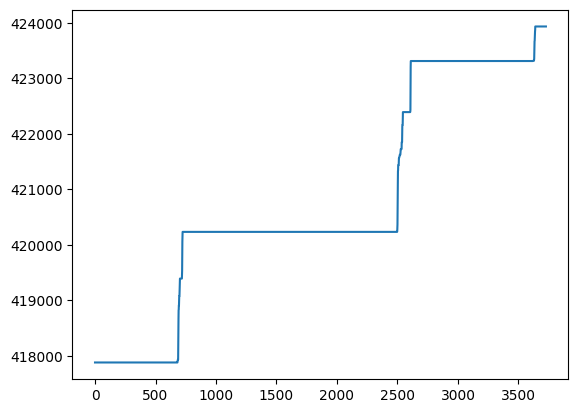

In [34]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append(float(unit.iloc[i,4]))
    x_axis.append(i)
    date.append(unit.iloc[i,5])
    raw_data_.append(unit.iloc[i,6])

#print("Delta odometer: ",y_axis[170]-y_axis[133],'meters')

for i in range(0,len(odometer)):
    print(date[i],'->',x_axis[i],'->',y_axis[i],'->',raw_data_[i])

print(odometer[len(odometer)-1]-odometer[0])
plt.plot(x_axis,y_axis)

Speed

In [35]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
#unit_aux['Odometer in meters']=0.0
speed=[]
date=[]
raw=[]
unit_speed=pd.DataFrame()
unit=pd.DataFrame()

for i in range(0,unit_aux.shape[0]):
    try:
        lbs_ind=(bin(int(unit_aux.iloc[i,2][50:52],16) & 64))
        if lbs_ind=='0b1000000':
            speed.append(int(unit_aux.iloc[i,2][142:145]))  
            date.append(unit_aux.iloc[i,2][106:118])
            raw.append(unit_aux.iloc[i,2])
            #print(lbs_ind)

    except:
        pass    

unit_speed['Speed']=speed
unit_speed['Date']=date
unit_speed['Raw data']=raw

unit=unit_speed.sort_values('Date',ascending=True)

print(unit.info())

<class 'pandas.DataFrame'>
Index: 3728 entries, 0 to 3727
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Speed     3728 non-null   int64
 1   Date      3728 non-null   str  
 2   Raw data  3728 non-null   str  
dtypes: int64(1), str(2)
memory usage: 116.5 KB
None


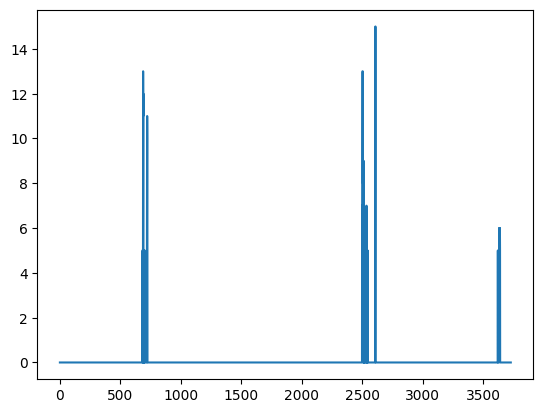

In [36]:
y_axis=[]
x_axis=[]
date=[]
raw_data_=[]

for i in range(0,unit.shape[0]):
    #print(float(fsq694_m_odometer.iloc[i,6][8:15]))
    y_axis.append(float(unit.iloc[i,0]))
    x_axis.append(i)
    date.append(unit.iloc[i,1])
    raw_data_.append(unit.iloc[i,2])

plt.plot(x_axis,y_axis)

In [37]:
print("Min speed: ",min(y_axis),'km/h',"Max speed: ",max(y_axis),'km/h',"Average speed: ",statistics.mean(y_axis),'km/h',"Mode: ",statistics.mode(y_axis),'km/h',"Median: ",statistics.median(y_axis),'km/h')

for i in range(0,len(y_axis)):
    #if y_axis[i]>0 and y_axis[i]<5:
    if y_axis[i]==0:
        print(y_axis[i],date[i],raw_data_[i])
print("Total registers: ",i)

Min speed:  0.0 km/h Max speed:  15.0 km/h Average speed:  0.10434549356223176 km/h Mode:  0.0 km/h Median:  0.0 km/h
0.0 260921000037 0x2525130059EBE80869487060173472003C38402D0000003A520000000700644100000000000000FFFFFFFFFFFF00D50006605600260921000037CDDC8044E99698C29C3A66400000014603931257FFFFFF0000210000FFFFFF
0.0 260921000138 0x2525130059EBE90869487060173472003C38402D0000003E500000000700644100000000000000FFFFFFFFFFFF00D50006605600260921000138CDDC8044E99698C29C3A66400000014603931252FFFFFF0000210000FFFFFF
0.0 260921000219 0x252514005938D60869487060173472003C38402D00000037520000000700644100000000000000FFFFFFFFFFFF18D50006605600260921000219CDDC8044E99698C29C3A66400000014603931258FFFFFF0000210000FFFFFF
0.0 260921000338 0x2525130059EBEA0869487060173472003C38402D00000037510000000700644100000000000000FFFFFFFFFFFF00D50006605600260921000338CDDC8044E99698C29C3A66400000014603931254FFFFFF0000210000FFFFFF
0.0 260921000438 0x2525130059EBEB0869487060173472003C38402D0000003351000000070064410000000

Historical events (Script uner trial stage)

In [38]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
satellite_number=[]
satellite_connection_indicator=[]
date=[]
raw=[]
num_events=0
speed_aux=[]

for i in range(0,unit_aux.shape[0]):
    satellite_number.append(int(unit_aux.iloc[i,2][50:52],16) & 31)
    satellite_connection_indicator.append(int(unit_aux.iloc[i,2][50:52],16) & 0b10000000)
    date.append(unit_aux.iloc[i,2][106:118])
    speed_aux.append(int(unit_aux.iloc[i,2][142:145])) 
    raw.append(unit_aux.iloc[i,2])    

unit_aux['Satellites']=satellite_number
unit_aux['Satellite_connection_indicator']=satellite_connection_indicator
unit_aux['Raw data']=raw
unit_aux['Speed']=speed_aux
unit_aux['date']=date

unit=unit_aux.sort_values('date',ascending=True)

unit.info()

for i in range(0,unit.shape[0]):
    if unit.iloc[i,5]>0:
        num_events=num_events+1
        print(unit_aux.iloc[i,4],'->', unit_aux.iloc[i,5], '->',unit_aux.iloc[i,6],'->',unit_aux.iloc[i,8],'->',unit_aux.iloc[i,7])

print("Eventos históricos: ",num_events)

<class 'pandas.DataFrame'>
Index: 3728 entries, 0 to 5899
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   Created                         3728 non-null   str  
 1   Message                         3728 non-null   str  
 2   Status                          3728 non-null   str  
 3   Headers                         3728 non-null   str  
 4   Satellites                      3728 non-null   int64
 5   Satellite_connection_indicator  3728 non-null   int64
 6   Raw data                        3728 non-null   str  
 7   Speed                           3728 non-null   int64
 8   date                            3728 non-null   str  
dtypes: int64(3), str(6)
memory usage: 291.2 KB
16 -> 0 -> 0x2525130059EC600869487060173472003C38402D0000003A500000000700644100000000000000FFFFFFFFFFFF00D50006605600260921023137CDDC8044E99698C29C3A66400000014603931252FFFFFF0000200000FFFFFF -> 260921023137 -> 0


Satellites Number

In [39]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
satellite_number=[]
satellite_connection_indicator=[]
date=[]
raw=[]
num_events=0

for i in range(0,unit_aux.shape[0]):
    satellite_number.append(int(unit_aux.iloc[i,2][50:52],16) & 31)
    satellite_connection_indicator.append(int(unit_aux.iloc[i,2][50:52],16) & 128)
    date.append(unit_aux.iloc[i,2][106:118])
    raw.append(unit_aux.iloc[i,2])    

unit_aux['Satellites']=satellite_number
unit_aux['Satellite_connection_indicator']=satellite_connection_indicator
unit_aux['Raw data']=raw
unit_aux['date']=date

unit=unit_aux.sort_values('date',ascending=True)

unit.info()

for i in range(0,unit.shape[0]):
    if unit.iloc[i,4]<2:
        num_events=num_events+1
        print(unit.iloc[i,5],'->', unit.iloc[i,0], '->',unit.iloc[i,4],'->',unit.iloc[i,6])

print("Eventos históricos: ",num_events)

<class 'pandas.DataFrame'>
Index: 3728 entries, 0 to 5899
Data columns (total 8 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   Created                         3728 non-null   str  
 1   Message                         3728 non-null   str  
 2   Status                          3728 non-null   str  
 3   Headers                         3728 non-null   str  
 4   Satellites                      3728 non-null   int64
 5   Satellite_connection_indicator  3728 non-null   int64
 6   Raw data                        3728 non-null   str  
 7   date                            3728 non-null   str  
dtypes: int64(2), str(6)
memory usage: 262.1 KB
Eventos históricos:  0


Coordinates

In [40]:
import struct

unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
latitude=[]
lat_aux=[]
longitude=[]
lon_aux=[]
speed=[]
date=[]
raw=[]
num_events=0

for i in range(0,unit_aux.shape[0]):
    latitude.append(unit_aux.iloc[i,2][134:142])
    longitude.append(unit_aux.iloc[i,2][126:134])
    lon_aux.append(struct.unpack('<f', bytes.fromhex(unit_aux.iloc[i,2][126:134]))[0])
    lat_aux.append(struct.unpack('<f', bytes.fromhex(unit_aux.iloc[i,2][134:142]))[0])    
    speed.append(int(unit_aux.iloc[i,2][142:145],16))
    date.append(unit_aux.iloc[i,2][106:118])
    raw.append(unit_aux.iloc[i,2])    

unit_aux['Latitude']=latitude
unit_aux['Latitude_decoded']=lat_aux
unit_aux['Longitude']=longitude
unit_aux['Longitude_decoded']=lon_aux
unit_aux['Raw data']=raw
unit_aux['Date']=date
unit_aux['Speed']=speed

unit=unit_aux.sort_values('Date',ascending=True)

print(unit.info())

for i in range(0,unit.shape[0]):
    num_events=num_events+1
    print(unit.iloc[i,9],'->', unit.iloc[i,4], '->',unit.iloc[i,5],'->',unit.iloc[i,6],'->',unit.iloc[i,7],unit.iloc[i,8])

<class 'pandas.DataFrame'>
Index: 3728 entries, 0 to 5899
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Created            3728 non-null   str    
 1   Message            3728 non-null   str    
 2   Status             3728 non-null   str    
 3   Headers            3728 non-null   str    
 4   Latitude           3728 non-null   str    
 5   Latitude_decoded   3728 non-null   float64
 6   Longitude          3728 non-null   str    
 7   Longitude_decoded  3728 non-null   float64
 8   Raw data           3728 non-null   str    
 9   Date               3728 non-null   str    
 10  Speed              3728 non-null   int64  
dtypes: float64(2), int64(1), str(8)
memory usage: 349.5 KB
None
260921000037 -> 9C3A6640 -> 3.59732723236084 -> E99698C2 -> -76.29474639892578 0x2525130059EBE80869487060173472003C38402D0000003A520000000700644100000000000000FFFFFFFFFFFF00D50006605600260921000037CDDC8044E99698C29C3A664

In/Outs

15      14                 13      12      11      10      09      08       07 06 05 04 03 02 01 00
Power   Ignition/Input0    Input1  Input2  Input3  Input4  Input5  Input0

15=0, Connected
15=1. Disconnected

In [41]:
unit_13=raw_data[raw_data['Status'].str.contains('0x252513')]
unit_14=raw_data[raw_data['Status'].str.contains('0x252514')]
unit_aux=pd.concat([unit_13,unit_14])
unit_aux.info()
aux_cad=[]
aux_date=[]
aux_raw_data=[]
aux_input_number=[]
in_outs=[]

#unit_aux.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sym\concatenated.csv')

for i in range(0,unit_aux.shape[0]):
    long_cad=len(unit_aux.iloc[i,2])
    if ((long_cad>48) & (long_cad<204)):
        aux_cad.append(unit_aux.iloc[i,2])   

for i in range(0,len(aux_cad)):
    aux_value=aux_cad[i][64:68]
    aux_date.append(aux_cad[i][106:118])
    aux_raw_data.append(aux_cad[i])
    in_outs.append(bin (int (aux_cad[i][64:68],16) ))      

unit_=pd.DataFrame()
unit_['in and outs']=in_outs
unit_['date']=aux_date
unit_['raw data']=aux_raw_data

in_outs_df=unit_.sort_values('date',ascending=True)

in_outs_df.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\la_concepcion\in_outs.csv')

<class 'pandas.DataFrame'>
Index: 3728 entries, 0 to 5899
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Created  3728 non-null   str  
 1   Message  3728 non-null   str  
 2   Status   3728 non-null   str  
 3   Headers  3728 non-null   str  
dtypes: str(4)
memory usage: 145.6 KB


Ignition

In [42]:
in_outs_df.info()

for i in range(0,in_outs_df.shape[0]):
    length=len(in_outs_df.iloc[i,0])
    if length>16:
        aux_ign=in_outs_df.iloc[i,0][2:3]
        if aux_ign=='1':
            print("Ignition On",in_outs_df.iloc[i,0])
        if aux_ign=='0':
            print("Ignition Off",in_outs_df.iloc[i,0])
    else:
        aux_ign=in_outs_df.iloc[i,0][2:3]
        if aux_ign=='1':
            print("Ignition On",in_outs_df.iloc[i,0])
        if aux_ign=='0':
            print("Ignition Off",in_outs_df.iloc[i,0])

<class 'pandas.DataFrame'>
Index: 3721 entries, 0 to 3720
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   in and outs  3721 non-null   str  
 1   date         3721 non-null   str  
 2   raw data     3721 non-null   str  
dtypes: str(3)
memory usage: 116.3 KB
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 0b100000100000000
Ignition On 

Historical locations

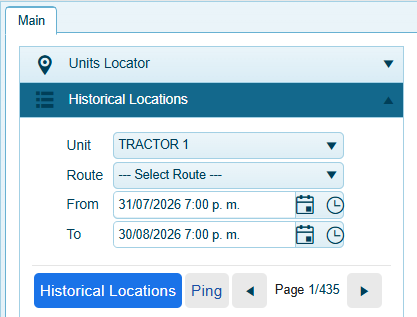

In [43]:
hl=pd.read_excel(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\la_concepcion\historicallocations.xlsx')
hl.info()
#Historical Locations since 31-07-2026 19:00 until 30-08-2026

<class 'pandas.DataFrame'>
RangeIndex: 43412 entries, 0 to 43411
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Sequence     43412 non-null  int64  
 1   Unit         43412 non-null  str    
 2   Events       43412 non-null  str    
 3   Date         43412 non-null  str    
 4   Landmark     23 non-null     str    
 5   Address      43412 non-null  str    
 6   Speed        43412 non-null  int64  
 7   Temperature  0 non-null      float64
 8   Driver       0 non-null      float64
 9   Latitude     43412 non-null  float64
 10  Longitude    43412 non-null  float64
dtypes: float64(4), int64(2), str(5)
memory usage: 3.6 MB


In [44]:
hl['Events'].value_counts()

Events
Idle - Stop       33002
Idle Alert         8377
Drive              1950
End Idle Alert       42
Fuel Raising         13
Geofence IN          12
Geofence OUT         11
Panic button          3
Fuel Dropping         2
Name: count, dtype: int64

In [45]:
hl_speed0=hl[hl['Speed']==0]
hl_speed0.info()

<class 'pandas.DataFrame'>
Index: 41241 entries, 0 to 43411
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Sequence     41241 non-null  int64  
 1   Unit         41241 non-null  str    
 2   Events       41241 non-null  str    
 3   Date         41241 non-null  str    
 4   Landmark     4 non-null      str    
 5   Address      41241 non-null  str    
 6   Speed        41241 non-null  int64  
 7   Temperature  0 non-null      float64
 8   Driver       0 non-null      float64
 9   Latitude     41241 non-null  float64
 10  Longitude    41241 non-null  float64
dtypes: float64(4), int64(2), str(5)
memory usage: 3.8 MB
